# Un solo core · reducción de A con parámetros fijos

Referencia: **Propuesta · un core, sin O₂, E1 del notebook09**, A=0.3. Se comparan A=0.2, 0.1 y 0.0, sin optimización ni ajuste de ganancia, transferencia, saturación, actividad, tiempos o theta_nv2. Se conservan condiciones iniciales, temperaturas de logs, dosis y calendario, Cd0=0 y horizontes del09. LAB017 tiene un pulso único de0.28g/L.

Cada alternativa se muestra en su propia figura: referencia azul, alternativa verde y medianas horarias medidas negras. Hay vistas completas y ampliaciones separadas del pico posterior al pulso y de la cola. No se superponen todos los escenarios en una figura.

La fuente es \(q_{\rm prod}=\mathrm{gate}\,a(t)M(t)(44.01/46.07)(\beta_G+\beta_F)X\), una única química nutrida. \(M=1+A\sum_p(\Delta N_p/N_{\rm ref})h_p(t)\), con h normalizado por máximo analítico. Se conservan tau_r=4h, tau_d=12h, actividad final0.25 y rampa64.6587h. El depósito y la liberación son históricos: \(\dot C_d=q_{\rm prod}-q_{\rm gas}\), \(q_{\rm gas}=kC_d[0.05+0.95C_d/(C_d+C_{\rm sat})]\), salida=ganancia·qgas.

No se ejecutan las calibraciones del09. Se reconstruye sólo el contexto de un core con sus mismas entradas y se recuperan sus coeficientes E1 a precisión completa desde el EXECUTED. No se calcula core0. El09 es dependencia de procedencia explícita y queda protegido por hash.

Las muestras son las mismas medianas horarias de RAW ya convertida por volumen remanente, sin filtrar la predicción. Se conserva la política de fin del lector histórico. LAB019–021 se rotulan «Calibración previa CO₂» y LAB016–018 «Holdout previo CO₂»: aquí no se calibra ninguno y no se selecciona un valor de A como ajuste validado.

Métricas ordinarias y censuradas (observación<0.05: max(pred−0.05,0)). Pico posterior: máximo entre el pulso y24h después. Cola tardía: desde32h después del pulso hasta el corte; representa más de2.5 veces tau_d y se mantiene fija entre escenarios. Se imprimen ventanas/cobertura. Los máximos predicho y medido se comparan sobre los mismos tiempos de observación, no se interpretan los picos medidos como efecto exclusivo de nutrición. Se incluye vista de Cd para ver la memoria del depósito. Química idéntica y sin cambios de parámetros; no se exportan CSV/PNG al proyecto.


In [1]:
from pathlib import Path
import sys,json,hashlib
import numpy as np,pandas as pd
import matplotlib.pyplot as plt
from dataclasses import replace
from IPython.display import display,Markdown
ROOT=next(p for p in (Path.cwd(),*Path.cwd().parents) if (p/'src/wine_fermentation').is_dir())
assert Path(sys.prefix).name.lower()=='fermentation'
sys.path.insert(0,str(ROOT/'src'));sys.dont_write_bytecode=True
from wine_fermentation.models.historical import co2 as gas,kinetics
from wine_fermentation.models.historical.calibration import load,release_forward,Search
from wine_fermentation.comparison import observations
NAME='10_single_core_A_sensitivity'
protected=[p for folder in ('src','configs','data','notebooks','results') for p in (ROOT/folder).rglob('*') if p.is_file() and '__pycache__' not in str(p) and not p.name.startswith(NAME+'.')]
before={p:hashlib.sha256(p.read_bytes()).hexdigest() for p in protected}
old=__import__('nbformat').read(ROOT/'notebooks/diagnostics/09_historical_single_core.executed.ipynb',4)
stream=''.join(o.get('text','') for o in old.cells[4].outputs if o.output_type=='stream')
records=json.JSONDecoder().raw_decode(stream.split('PARAMETROS_COMPLETOS_SIN_EXPORTACION\n')[1])[0]
p0=next(r['parametros'] for r in records if r['caso']=='Propuesta · un core, sin O₂' and r['etapa']=='E1')
assert p0['A']==.3
theta=kinetics.normalize_parameters(json.loads((ROOT/'configs/theta/theta_nv2.json').read_text()))
theta_before=theta.copy();assert 0<theta['Yeg']<=.5114 and 0<theta['Yef']<=.5114
v=load(ROOT);LABS=['LAB019','LAB020','LAB021','LAB016','LAB017','LAB018']
batches=dict(v.batches);b=batches['LAB017'];events=b.pulses['N'];assert np.isclose(sum(d for t,d in events),.28)
batches['LAB017']=replace(b,pulses={**b.pulses,'N':((min(t for t,d in events),.28),)})
raw=pd.read_csv(ROOT/'data/processed/co2_mass_balance_lab016_021_g_l_h.csv',usecols=['lab','time_h','record_kind','co2_raw_g_l_h'])
obs=observations(raw);support={lab:obs[lab].loc[obs[lab].time_h.between(0,v.horizons[lab])].copy() for lab in LABS}
contexts={};calls=0
for lab,b in batches.items():
 f=gas.integrate_core(b,theta,b.time);calls+=1
 consumed=(f.G+f.F).iloc[0]-(f.G+f.F).to_numpy();z=np.clip((consumed-2.)/8.,0,1)
 contexts[lab]=dict(time=f.index.to_numpy(),dt=np.diff(f.index),gate=z*z*(3-2*z),q=gas.production(theta,b,f),
  sat_base=gas.csat(b,f,{'CO2sat_scale':1.}),events=b.pulses['N'],core=f)
assert calls==6 and all('q0' not in x and 'core0' not in x for x in contexts.values())
params={a:{**p0,'A':a} for a in [.3,.2,.1,0.]}
for a,p in params.items():assert {k:x for k,x in p.items() if k!='A'}=={k:x for k,x in p0.items() if k!='A'}
display(pd.Series(theta,name='theta_nv2 congelado'))
display(pd.Series(p0,name='Referencia E1; sólo cambia A'))
windows={}
for lab in LABS:
 pulse=batches[lab].pulses['N'][0][0];end=v.horizons[lab]
 windows[lab]={'Registro':(0,end),'Pico posterior':(pulse,min(pulse+24,end)),'Cola tardía':(pulse+32,end)}
display(pd.DataFrame([dict(LAB=lab,eventos=batches[lab].pulses['N'],corte=v.horizons[lab],**batches[lab].initials) for lab in LABS]))
display(pd.DataFrame([dict(LAB=lab,tramo=w,inicio=ab[0],fin=ab[1]) for lab,ww in windows.items() for w,ab in ww.items()]))


mu0         0.082780
betaG0      0.412766
betaF0      0.447244
Kn0         0.008996
Kg0         4.400775
Kf0        19.296084
Kig0      122.553899
Kie0      286.579410
Kd0         0.000228
Yxn         5.179898
Yxg         0.966094
Yxf         1.109896
Yeg         0.482075
Yef         0.483728
m0          0.018339
Name: theta_nv2 congelado, dtype: float64

kCO2_release_h                            2.348168
CO2sat_scale                                   2.5
O2_qmax_mg_gdw_h                              0.15
O2_initial_scale                            0.1954
pulse_t_rise_h                           64.658704
pulse_activity_gain                           0.25
chem_activation_start_fraction            0.735057
chem_activation_duration_fraction          1.06391
matrix_gain                               0.774287
A                                              0.3
tau_rise_h                                     4.0
tau_decay_h                                   12.0
N_ref_g_l                                     0.14
kernel_normalization                 analytic_peak
activation_start_g_l                           2.0
activation_width_g_l                           8.0
Name: Referencia E1; sólo cambia A, dtype: object

,LAB,eventos,corte,X,N,G,F,E
0,LAB019,"((64.33333333333277, 0.08),)",166.000000,0.283162,0.230025,79.190000,78.970000,12.075372
1,LAB020,"((71.66666666666694, 0.08),)",172.333333,0.153342,0.225556,77.940000,79.520000,11.917524
2,LAB021,"((47.5, 0.08),)",166.000000,0.136153,0.231202,80.190000,81.040000,11.759676
3,LAB016,"((56.93555555555583, 0.14),)",151.100000,0.390000,0.214330,84.158815,88.341185,0.000000
4,LAB017,"((56.933611111110835, 0.28),)",141.000000,0.390000,0.214330,84.158815,88.341185,0.000000
5,LAB018,"((56.93166666666694, 0.14),)",141.000000,0.390000,0.214330,84.158815,88.341185,0.000000


,LAB,tramo,inicio,fin
0,LAB019,Registro,0.000000,166.000000
1,LAB019,Pico posterior,64.333333,88.333333
2,LAB019,Cola tardía,96.333333,166.000000
3,LAB020,Registro,0.000000,172.333333
4,LAB020,Pico posterior,71.666667,95.666667
5,LAB020,Cola tardía,103.666667,172.333333
6,LAB021,Registro,0.000000,166.000000
7,LAB021,Pico posterior,47.500000,71.500000
8,LAB021,Cola tardía,79.500000,166.000000
9,LAB016,Registro,0.000000,151.100000


In [2]:
curves={};rows=[];balance_errors=[]
for a,p in params.items():
 for lab,cx in contexts.items():
  r,M=Search.histories(cx['time'],cx['events'],p);activity=1+(p['pulse_activity_gain']-1)*r
  source=cx['gate']*activity*M*cx['q']
  pred,cd,qgas=release_forward({**cx,'source':source},p)
  err=np.max(abs(np.diff(cd)-cx['dt']*(source[:-1]-qgas[1:])))
  balance_errors.append(err);assert err<1e-9 and cd[0]==0 and cd.min()>=0 and qgas.min()>=-1e-12
  curves[a,lab]=pd.DataFrame(dict(qpred=pred,Cd=cd,qprod=source,M=M),index=cx['time'])
  o=support[lab]
  for window,(start,end) in windows[lab].items():
   z=o.loc[o.time_h.between(start,end)];t=z.time_h.to_numpy();y=z.co2_raw_g_l_h.to_numpy()
   assert len(t)>=2
   yp=np.interp(t,cx['time'],pred);e=yp-y;ce=np.where(y<.05,np.maximum(yp-.05,0),e)
   rows.append(dict(A=a,LAB=lab,rol='Calibración previa' if lab in LABS[:3] else 'Holdout previo',tramo=window,n=len(t),
    RMSE=float(np.sqrt(np.mean(e*e))),RMSE_censurado=float(np.sqrt(np.mean(ce*ce))),sesgo=float(e.mean()),
    max_medido=float(y.max()),max_predicho=float(yp.max()),hora_max_predicho=float(t[np.argmax(yp)]),
    area_medida=float(np.trapz(y,t)),area_predicha=float(np.trapz(yp,t)),
    Cd_inicio=float(np.interp(start,cx['time'],cd)),Cd_fin=float(np.interp(end,cx['time'],cd))))
metrics=pd.DataFrame(rows)
with pd.option_context('display.max_rows',100):display(metrics.round(6))
display(metrics.groupby(['tramo','rol','A'])[['RMSE','sesgo','max_predicho','area_predicha']].mean().round(6))
# Baseline regression against the09 E1: means of ordinary RMSE by lab.
baseline=metrics.loc[metrics.A.eq(.3)&metrics.tramo.eq('Registro')].groupby('rol').RMSE.mean()
assert np.isclose(baseline['Calibración previa'],.130951,atol=1e-6)
assert np.isclose(baseline['Holdout previo'],.157588,atol=1e-6)
for lab in LABS:
 for a in [.2,.1,0.]:
  assert np.all(curves[a,lab].qprod<=curves[.3,lab].qprod+1e-12)
  assert np.all(curves[a,lab].Cd<=curves[.3,lab].Cd+1e-10)
assert theta==theta_before and calls==6


,A,LAB,rol,tramo,n,RMSE,RMSE_censurado,sesgo,max_medido,max_predicho,hora_max_predicho,area_medida,area_predicha,Cd_inicio,Cd_fin
0,0.3,LAB016,Holdout previo,Registro,152,0.161648,0.160177,0.031276,0.798634,0.924644,66.500278,46.204576,50.989398,0.000000,0.044640
1,0.3,LAB016,Holdout previo,Pico posterior,24,0.206590,0.206590,0.193308,0.744680,0.924644,66.500278,13.434586,17.997828,1.203883,1.214267
2,0.3,LAB016,Holdout previo,Cola tardía,63,0.095125,0.094426,-0.085074,0.400678,0.326589,89.498194,9.965113,4.667579,0.904269,0.044640
3,0.3,LAB017,Holdout previo,Registro,141,0.171471,0.170455,0.033293,0.853441,1.171254,67.497222,51.174978,55.873802,0.000000,0.025593
4,0.3,LAB017,Holdout previo,Pico posterior,24,0.295340,0.295340,0.272489,0.853441,1.171254,67.497222,17.025045,23.474118,1.204131,1.407830
5,0.3,LAB017,Holdout previo,Cola tardía,52,0.090211,0.089441,-0.073980,0.449963,0.306211,89.498611,7.658561,3.882012,0.877824,0.025593
6,0.3,LAB018,Holdout previo,Registro,141,0.139646,0.138702,0.020116,0.811461,0.915406,66.500139,48.014901,50.847923,0.000000,0.084959
7,0.3,LAB018,Holdout previo,Pico posterior,24,0.174211,0.174211,0.154083,0.736923,0.915406,66.500139,14.302186,17.941145,1.204094,1.218283
8,0.3,LAB018,Holdout previo,Cola tardía,52,0.076013,0.075404,-0.065581,0.375799,0.329887,89.498333,8.012121,4.624072,0.912085,0.084959
9,0.3,LAB019,Calibración previa,Registro,166,0.147565,0.146468,0.023517,0.758905,0.701281,71.498611,39.947815,43.865662,0.000000,0.052695


RMSE     sesgo  max_predicho  \
tramo          rol                A                                       
Cola tardía    Calibración previa 0.0  0.101105 -0.005825      0.367451   
                                  0.1  0.101098 -0.005443      0.370780   
                                  0.2  0.101098 -0.005062      0.374106   
                                  0.3  0.101103 -0.004681      0.377429   
               Holdout previo     0.0  0.090054 -0.077266      0.302822   
                                  0.1  0.089054 -0.076468      0.308864   
                                  0.2  0.088075 -0.075672      0.314888   
                                  0.3  0.087116 -0.074878      0.320896   
Pico posterior Calibración previa 0.0  0.131401 -0.101346      0.589521   
                                  0.1  0.119418 -0.081510      0.620465   
                                  0.2  0.114172 -0.061671      0.652549   
                                  0.3  0.114887 -0.041829      0.685093   
               Holdout previo     0.0  0.089476  0.027789      0.762261   
                                  0.1  0.115665  0.087383      0.838498   
                                  0.2  0.166682  0.146996      0.919619   
                                  0.3  0.225380  0.206627      1.003768   
Registro       Calibración previa 0.0  0.134424 -0.005929      0.589521   
                                  0.1  0.132630 -0.002632      0.620465   
                                  0.2  0.131471  0.000664      0.652549   
                                  0.3  0.130951  0.003960      0.685093   
               Holdout previo     0.0  0.132837 -0.004786      0.762261   
                                  0.1  0.135661  0.006219      0.838498   
                                  0.2  0.144323  0.017223      0.919619   
                                  0.3  0.157588  0.028228      1.003768   

                                       area_predicha  
tramo          rol                A                   
Cola tardía    Calibración previa 0.0       7.738076  
                                  0.1       7.765095  
                                  0.2       7.792096  
                                  0.3       7.819079  
               Holdout previo     0.0       4.270121  
                                  0.1       4.310581  
                                  0.2       4.350946  
                                  0.3       4.391221  
Pico posterior Calibración previa 0.0      12.586146  
                                  0.1      13.064465  
                                  0.2      13.542864  
                                  0.3      14.021340  
               Holdout previo     0.0      15.552980  
                                  0.1      16.969622  
                                  0.2      18.386765  
                                  0.3      19.804364  
Registro       Calibración previa 0.0      37.772225  
                                  0.1      38.325426  
                                  0.2      38.878628  
                                  0.3      39.431830  
               Holdout previo     0.0      47.831649  
                                  0.1      49.411225  
                                  0.2      50.990800  
                                  0.3      52.570375

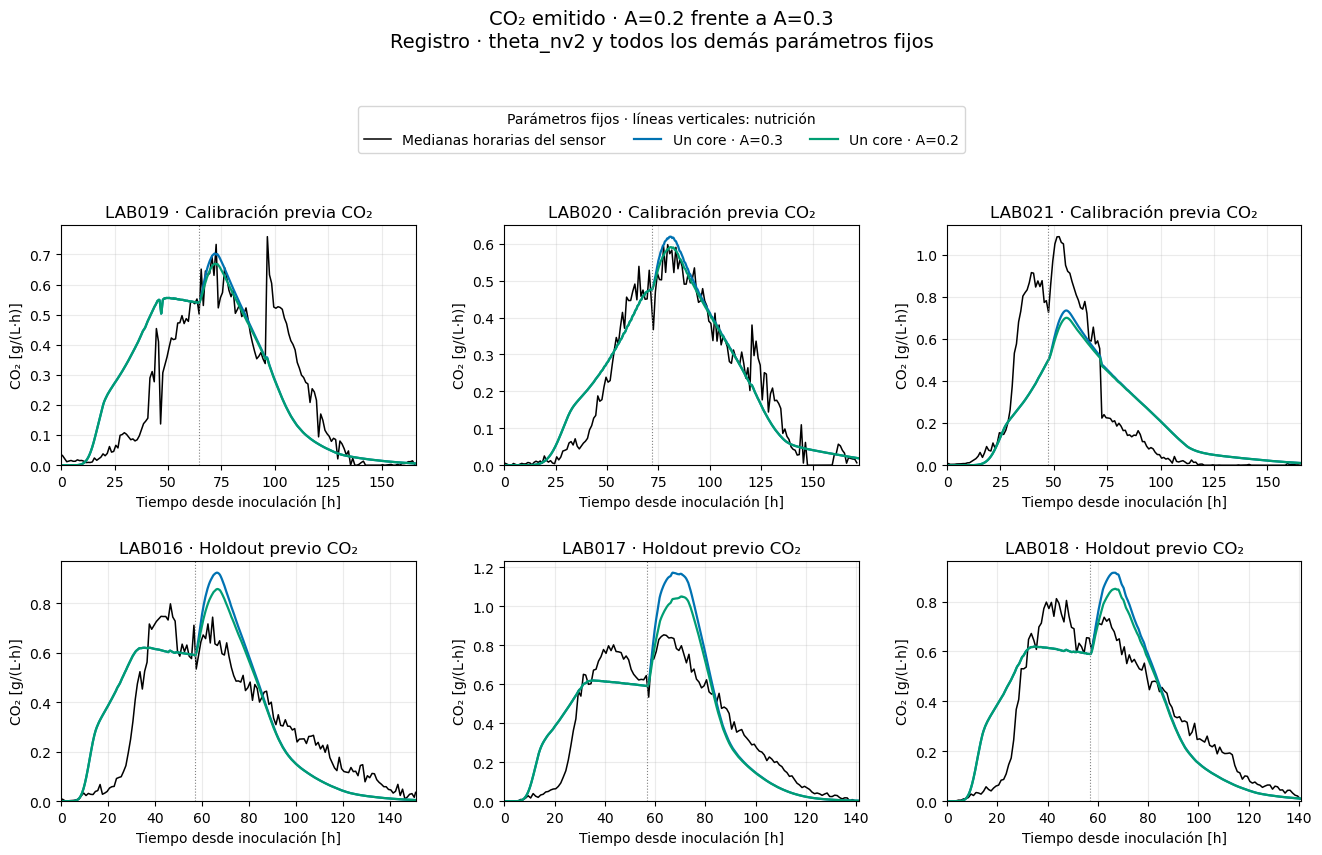

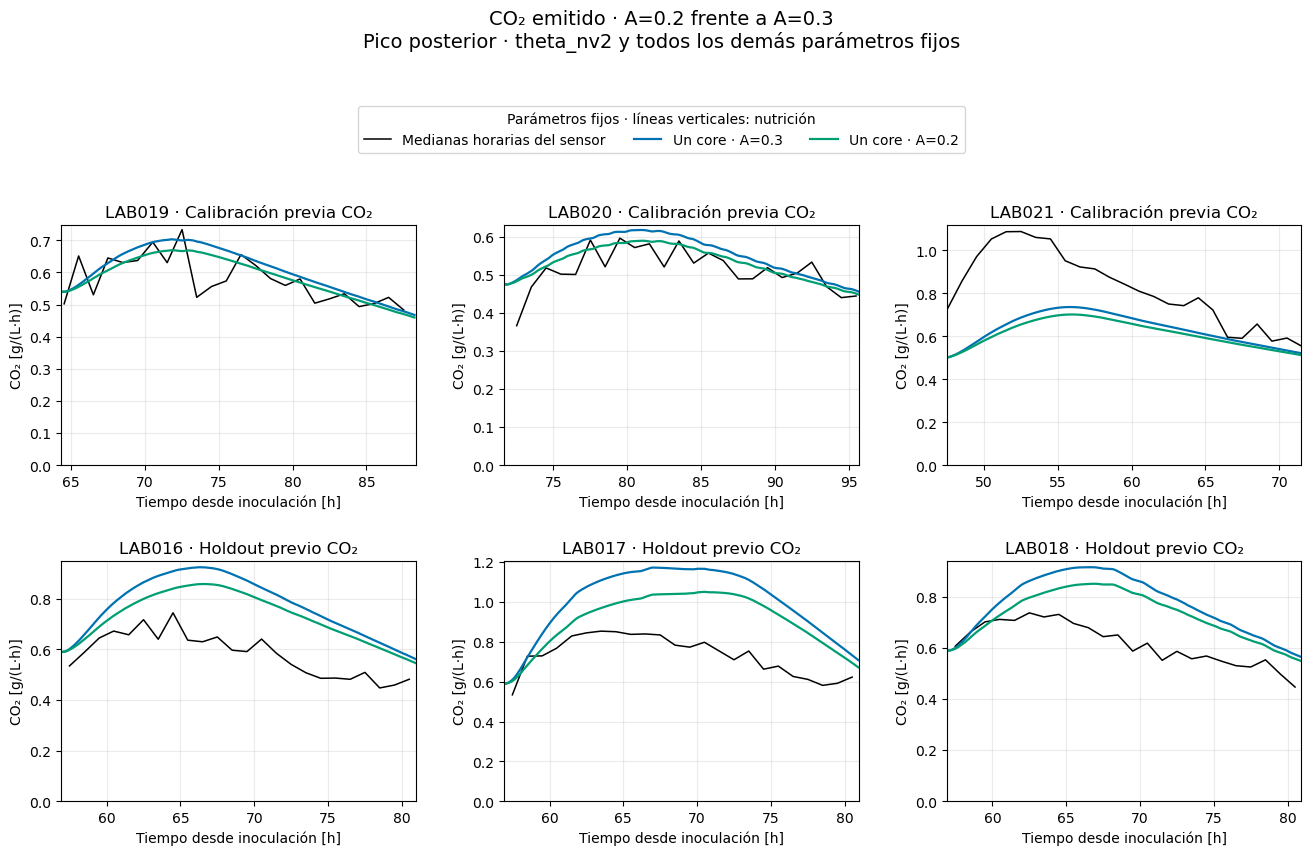

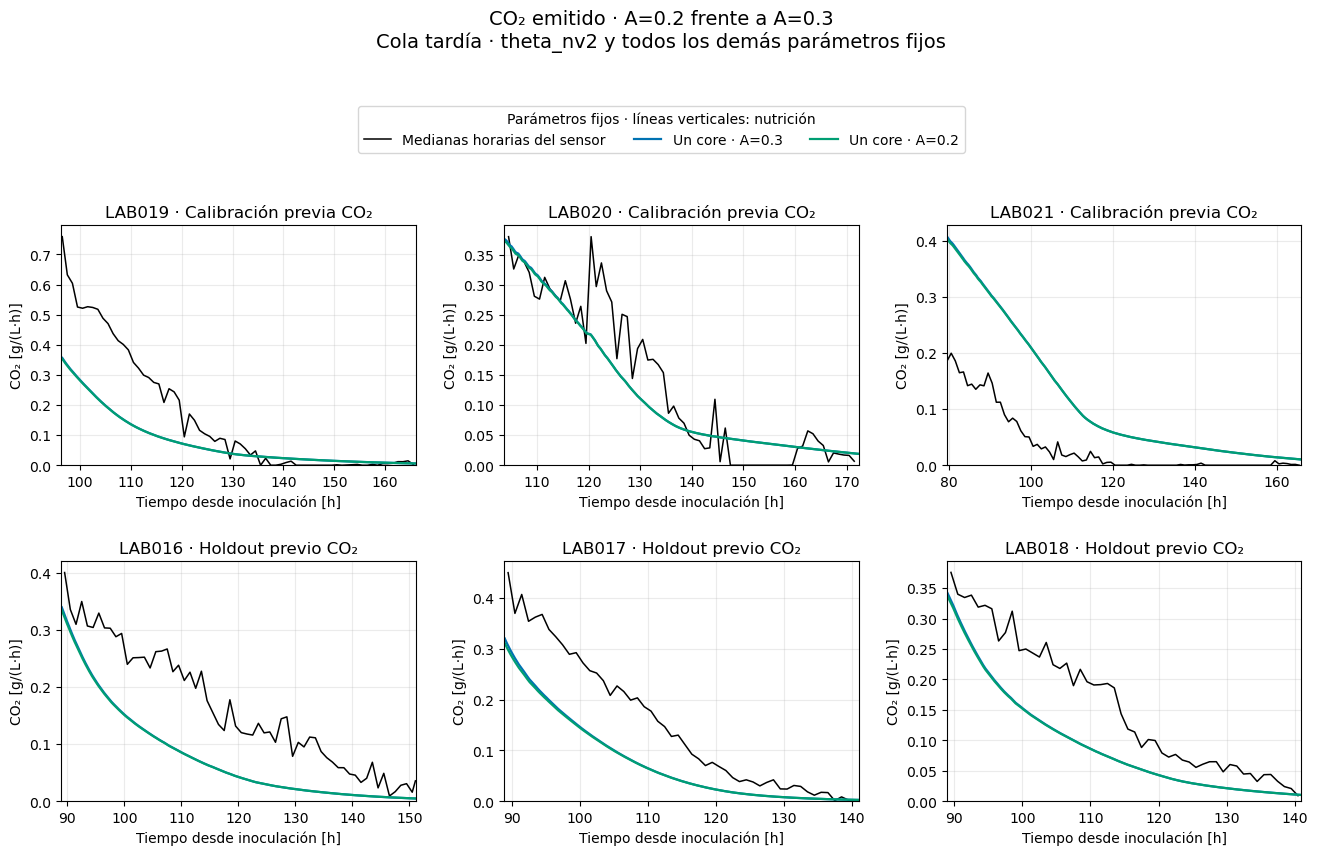

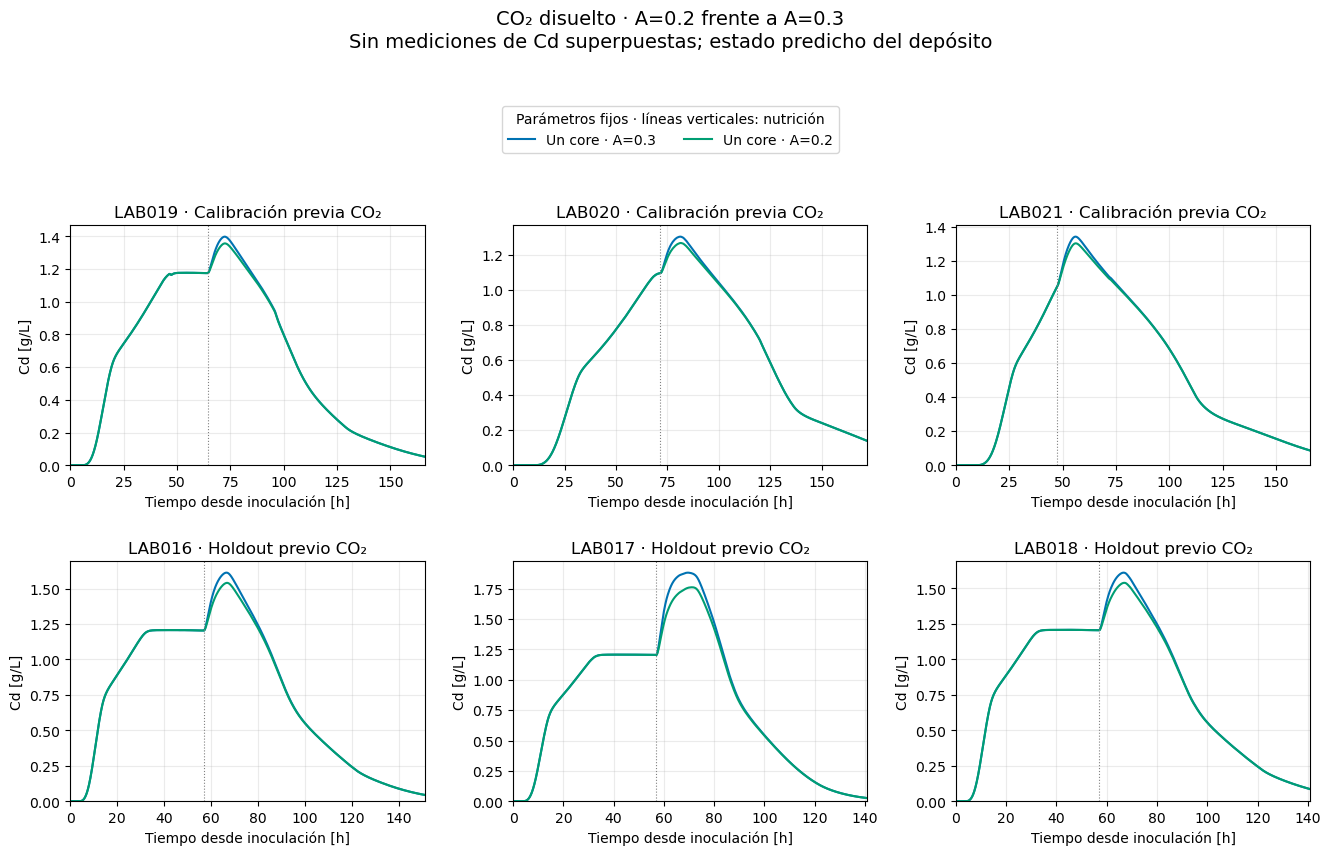

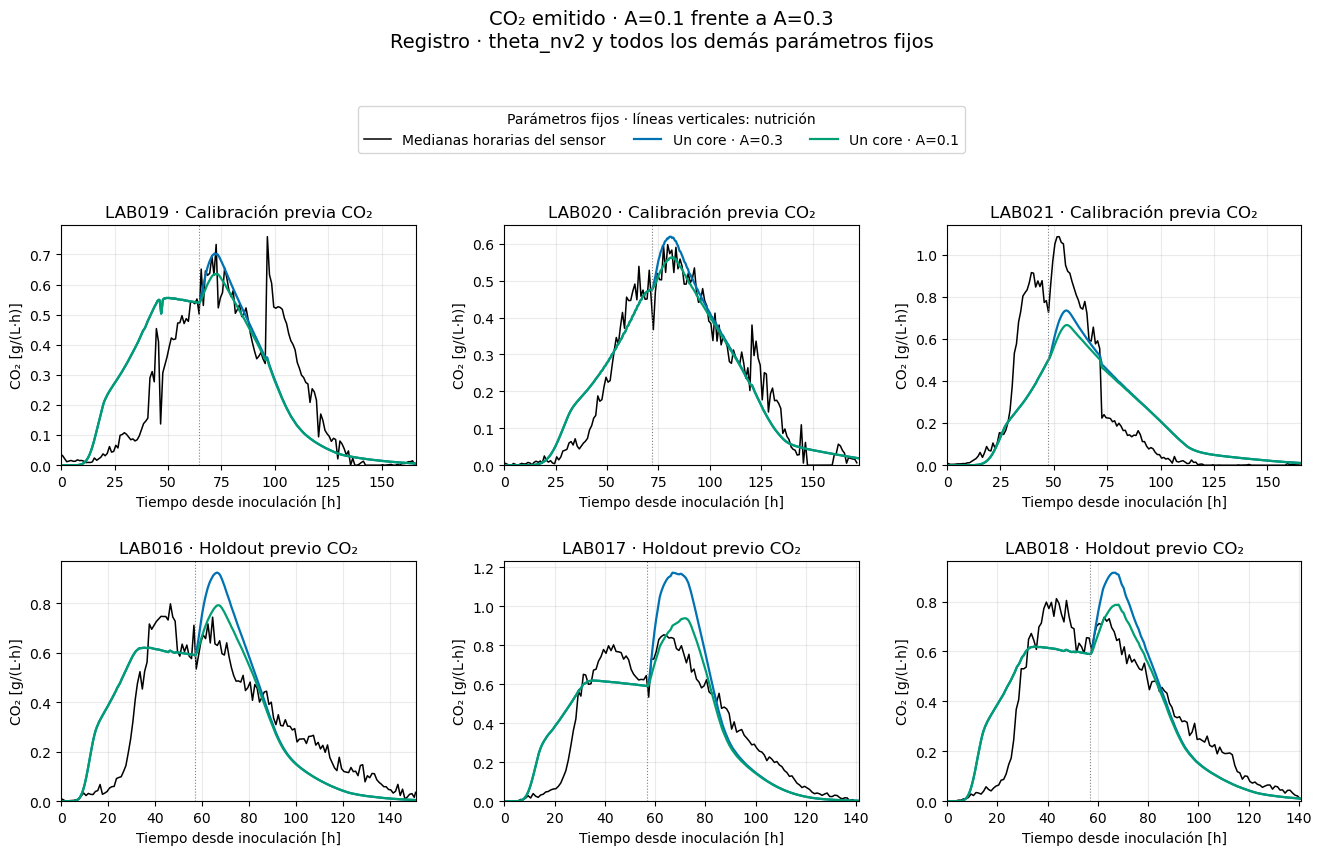

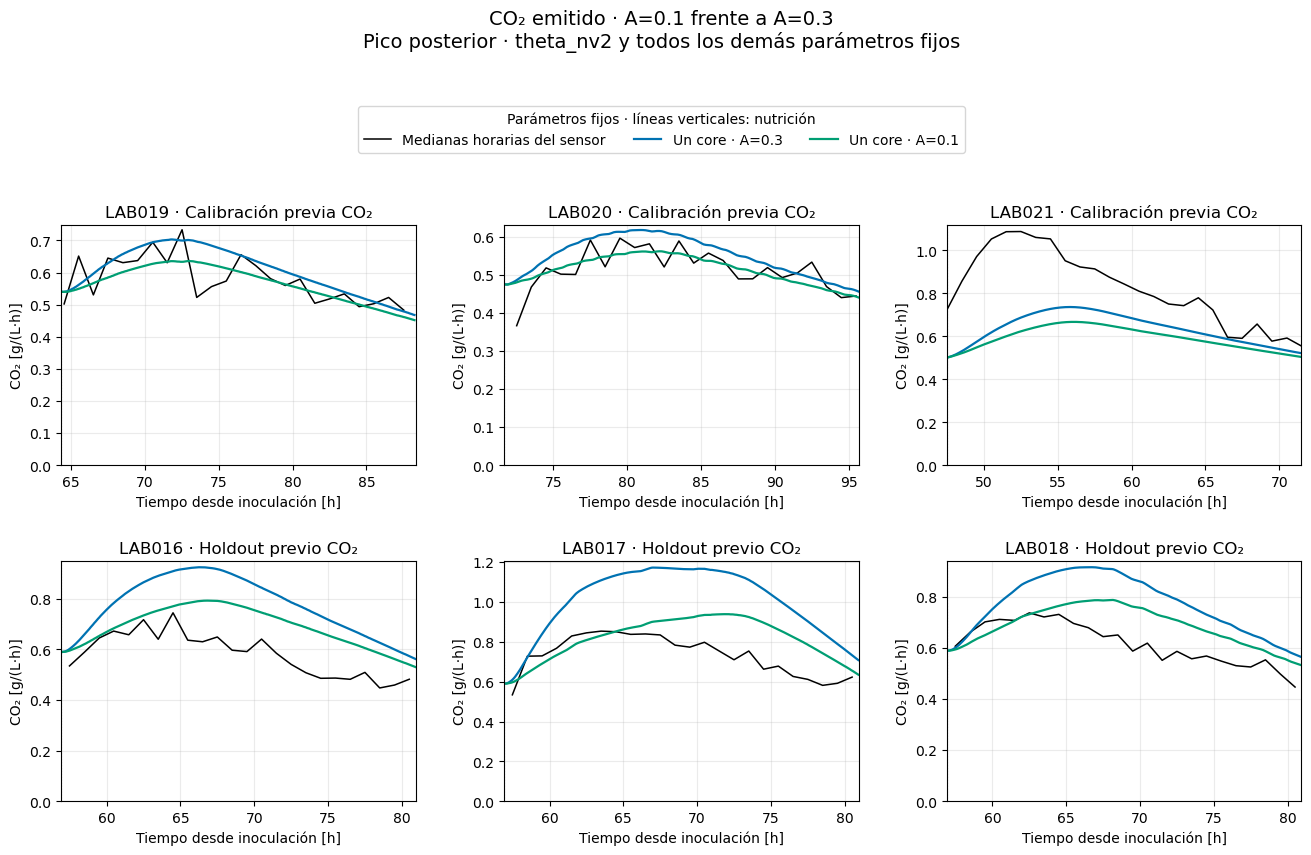

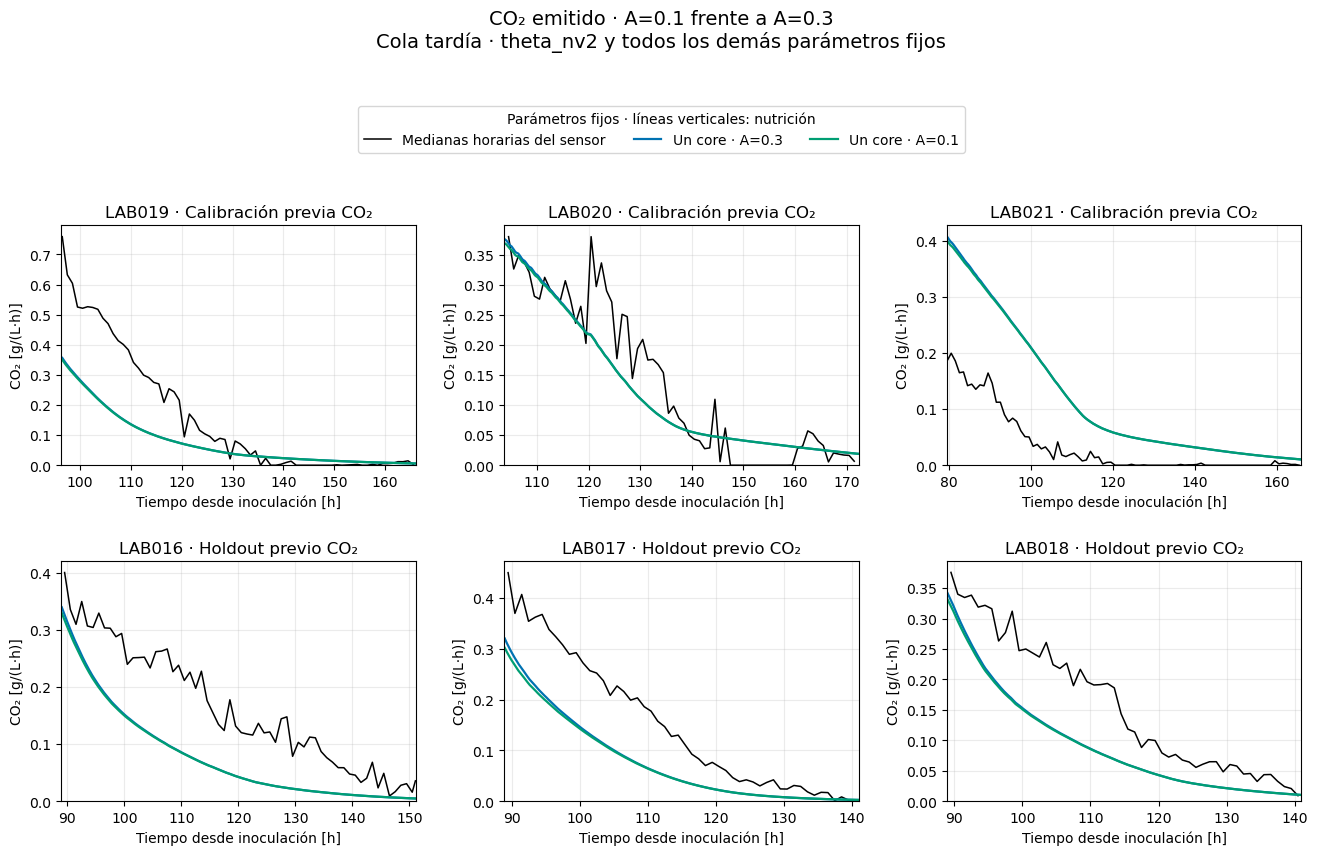

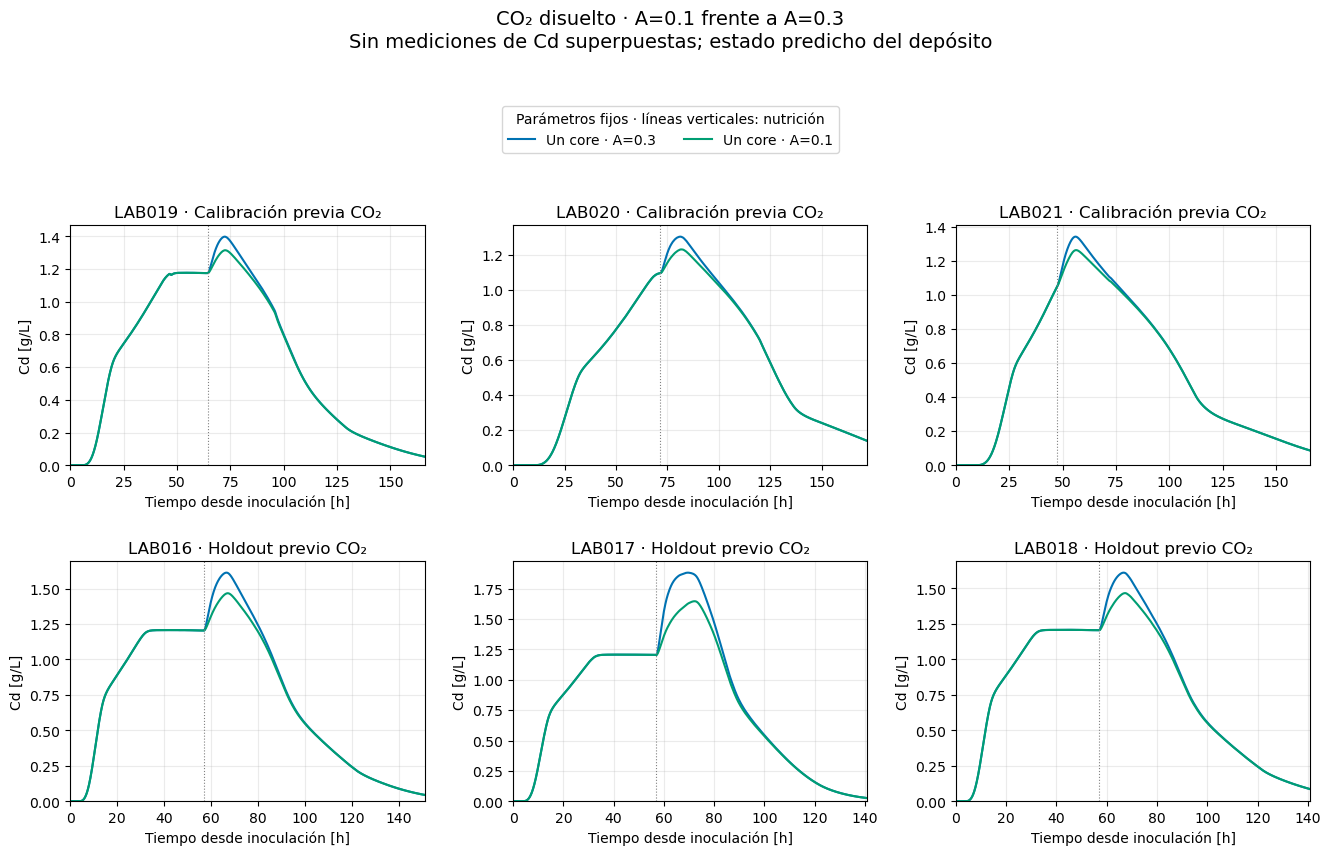

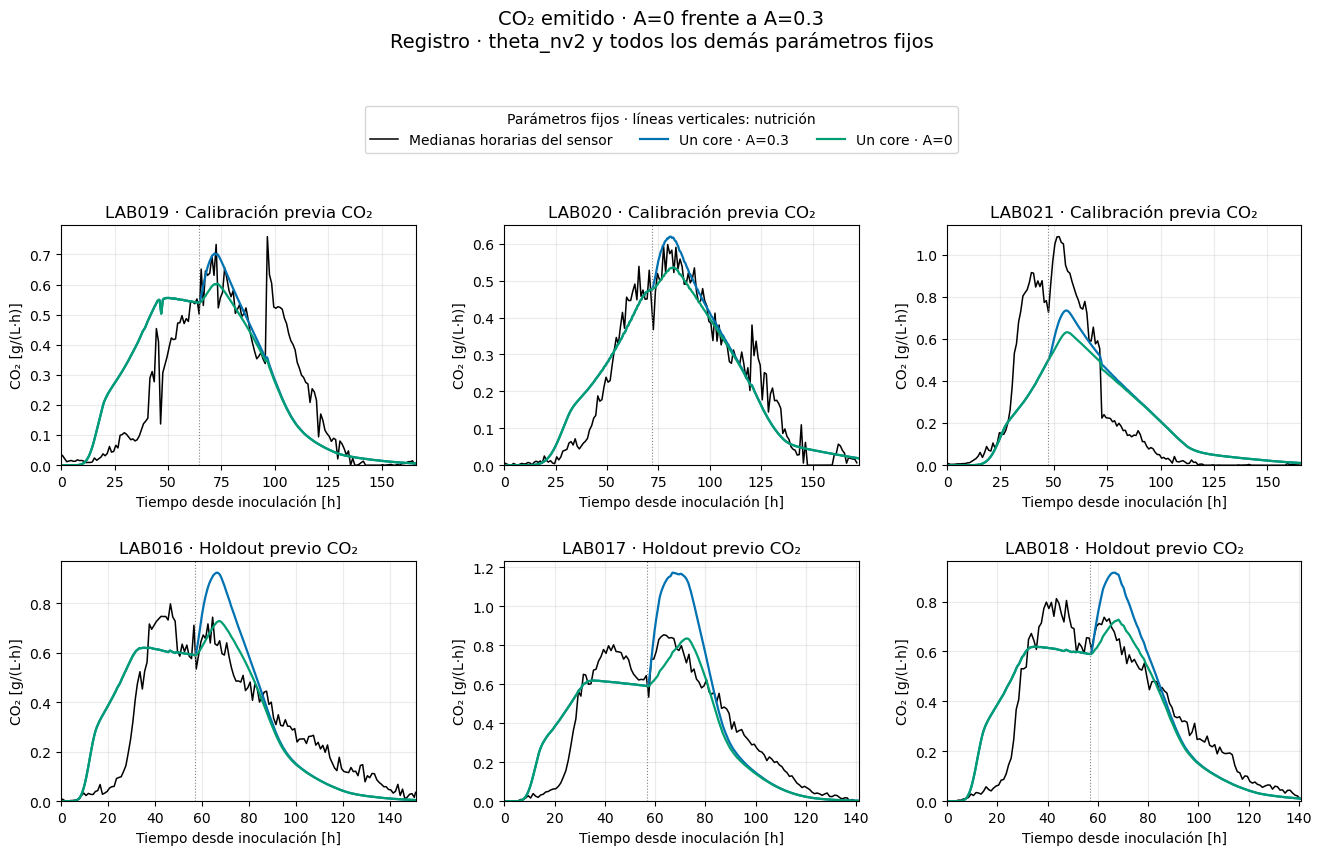

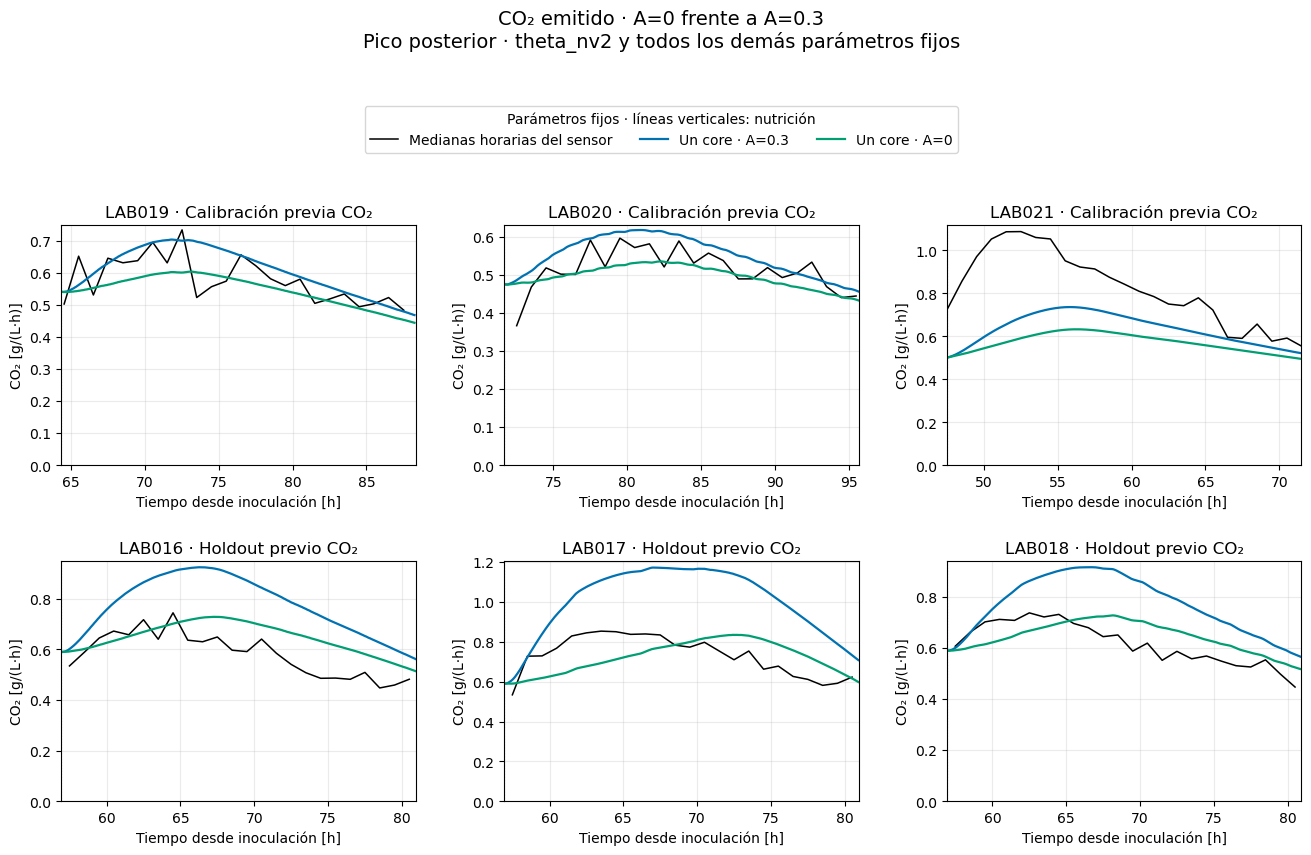

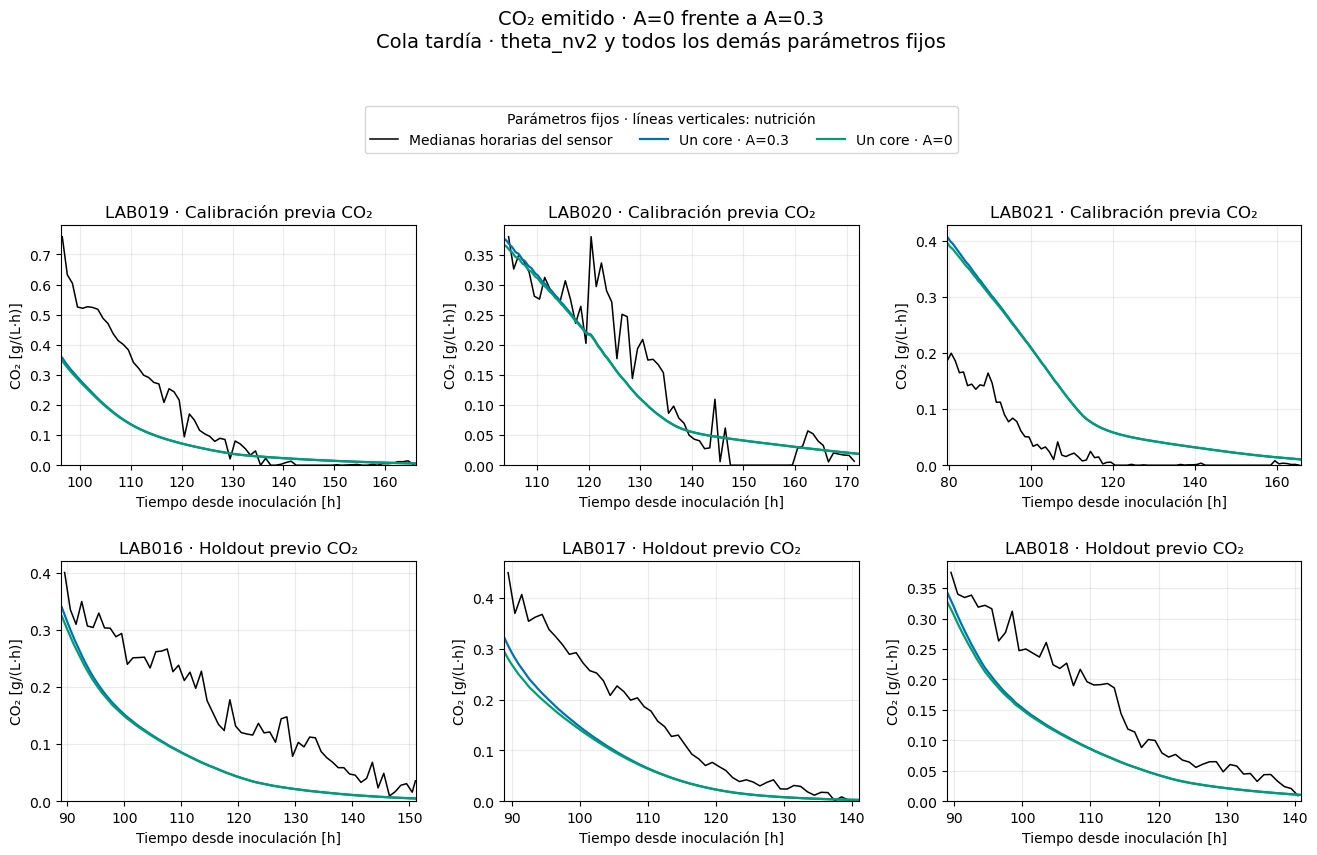

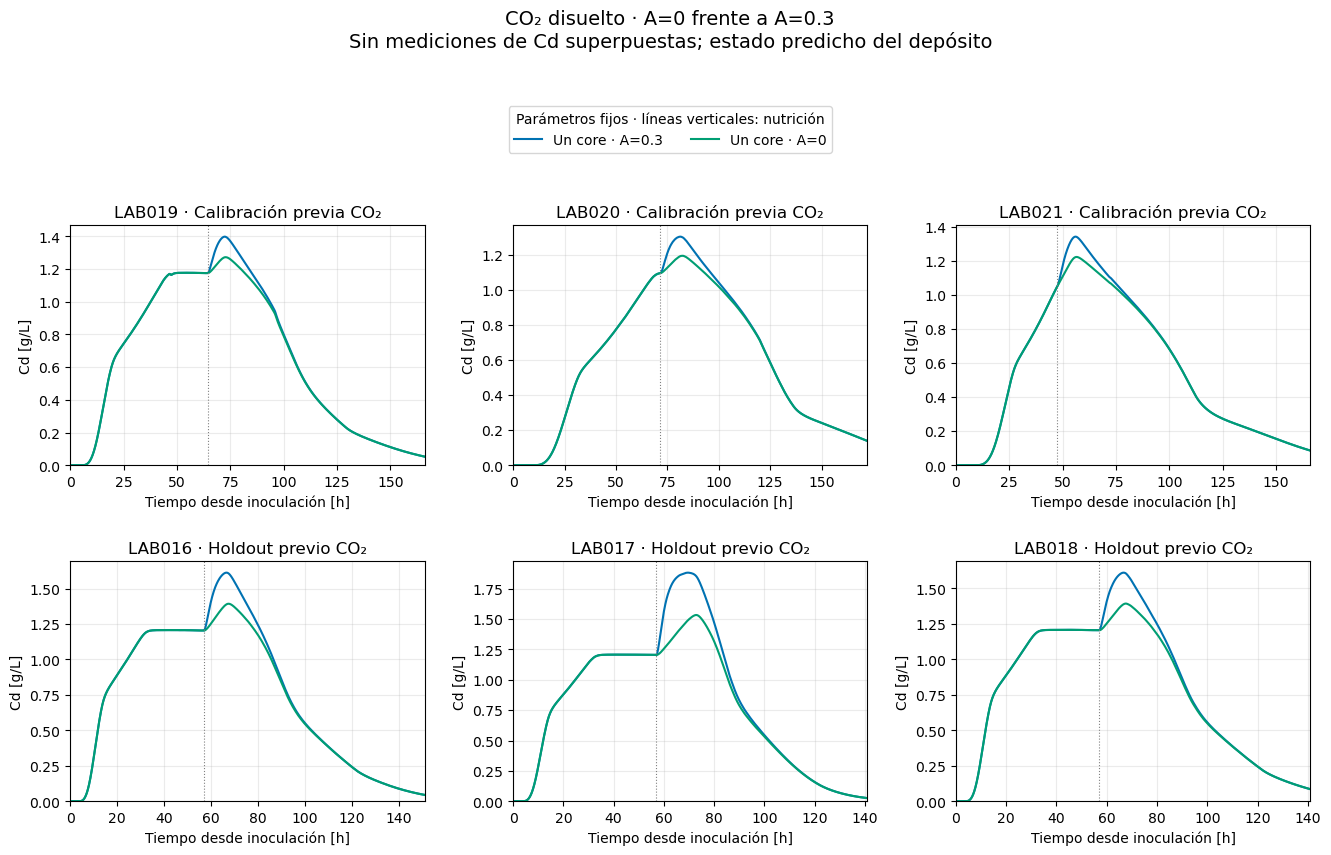

In [3]:
def finish(fig,axes,title,subtitle):
 fig.suptitle(title+'\n'+subtitle,y=.99,fontsize=14)
 items={}
 for ax in axes.flat:
  hh,ll=ax.get_legend_handles_labels()
  for h,l in zip(hh,ll):items.setdefault(l,h)
 fig.legend(items.values(),items.keys(),loc='upper center',bbox_to_anchor=(.5,.89),ncol=3,title='Parámetros fijos · líneas verticales: nutrición')
 fig.subplots_adjust(top=.75,hspace=.4,wspace=.25);plt.show()
for a in [.2,.1,0.]:
 for window in ['Registro','Pico posterior','Cola tardía']:
  fig,axes=plt.subplots(2,3,figsize=(16,9))
  for ax,lab in zip(axes.flat,LABS):
   start,end=windows[lab][window];o=support[lab];o=o.loc[o.time_h.between(start,end)]
   ax.plot(o.time_h,o.co2_raw_g_l_h,color='black',lw=1.1,label='Medianas horarias del sensor')
   for aa,color,labelf in [(.3,'#0072B2','Un core · A=0.3'),(a,'#009E73',f'Un core · A={a:g}')]:
    f=curves[aa,lab];m=(f.index>=start)&(f.index<=end)
    ax.plot(f.index[m],f.qpred[m],color=color,lw=1.6,label=labelf)
   for tp,d in batches[lab].pulses['N']:
    if start<=tp<=end:ax.axvline(tp,color='.5',ls=':',lw=.8)
   ax.set(title=lab+(' · Calibración previa CO₂' if lab in LABS[:3] else ' · Holdout previo CO₂'),
    xlabel='Tiempo desde inoculación [h]',ylabel='CO₂ [g/(L·h)]',xlim=(start,end))
   ax.set_ylim(bottom=0);ax.grid(alpha=.25)
  finish(fig,axes,f'CO₂ emitido · A={a:g} frente a A=0.3',window+' · theta_nv2 y todos los demás parámetros fijos')
 # Stored CO2 memory is shown separately, with only two curves.
 fig,axes=plt.subplots(2,3,figsize=(16,9))
 for ax,lab in zip(axes.flat,LABS):
  for aa,color in [(.3,'#0072B2'),(a,'#009E73')]:
   f=curves[aa,lab].loc[:v.horizons[lab]];ax.plot(f.index,f.Cd,color=color,label=f'Un core · A={aa:g}')
  for tp,d in batches[lab].pulses['N']:ax.axvline(tp,color='.5',ls=':',lw=.8)
  ax.set(title=lab+(' · Calibración previa CO₂' if lab in LABS[:3] else ' · Holdout previo CO₂'),
   xlabel='Tiempo desde inoculación [h]',ylabel='Cd [g/L]',xlim=(0,v.horizons[lab]));ax.set_ylim(bottom=0);ax.grid(alpha=.25)
 finish(fig,axes,f'CO₂ disuelto · A={a:g} frente a A=0.3','Sin mediciones de Cd superpuestas; estado predicho del depósito')


In [4]:
display(Markdown('## Verificación y resumen'))
assert all(hashlib.sha256(p.read_bytes()).hexdigest()==h for p,h in before.items())
assert theta==theta_before and calls==6
assert all({k:x for k,x in p.items() if k!='A'}=={k:x for k,x in p0.items() if k!='A'} for p in params.values())
print('Sólo cambió A. Cero optimizaciones, seis integraciones químicas, ninguna trayectoria sin nutrición.')
print('Modelos, parámetros, datos y notebooks anteriores intactos. Máximo error balance:',max(balance_errors))
summary=metrics.groupby(['tramo','rol','A']).RMSE.mean().unstack('A')
display(summary.round(6))
# Per-lab peak and tail changes retain signs and avoid an aggregate-only conclusion.
display(metrics.loc[metrics.tramo.ne('Registro'),['A','LAB','tramo','max_predicho','max_medido','RMSE','sesgo','area_predicha','area_medida']].round(6))
print('RESULTADOS_RESUMIDOS_JSON')
print(summary.reset_index().to_json(orient='records',force_ascii=False))


## Verificación y resumen

Sólo cambió A. Cero optimizaciones, seis integraciones químicas, ninguna trayectoria sin nutrición.
Modelos, parámetros, datos y notebooks anteriores intactos. Máximo error balance: 2.4036762164003633e-16


A                                       0.0       0.1       0.2       0.3
tramo          rol                                                       
Cola tardía    Calibración previa  0.101105  0.101098  0.101098  0.101103
               Holdout previo      0.090054  0.089054  0.088075  0.087116
Pico posterior Calibración previa  0.131401  0.119418  0.114172  0.114887
               Holdout previo      0.089476  0.115665  0.166682  0.225380
Registro       Calibración previa  0.134424  0.132630  0.131471  0.130951
               Holdout previo      0.132837  0.135661  0.144323  0.157588

,A,LAB,tramo,max_predicho,max_medido,RMSE,sesgo,area_predicha,area_medida
1,0.3,LAB016,Pico posterior,0.924644,0.744680,0.206590,0.193308,17.997828,13.434586
2,0.3,LAB016,Cola tardía,0.326589,0.400678,0.095125,-0.085074,4.667579,9.965113
4,0.3,LAB017,Pico posterior,1.171254,0.853441,0.295340,0.272489,23.474118,17.025045
5,0.3,LAB017,Cola tardía,0.306211,0.449963,0.090211,-0.073980,3.882012,7.658561
7,0.3,LAB018,Pico posterior,0.915406,0.736923,0.174211,0.154083,17.941145,14.302186
8,0.3,LAB018,Cola tardía,0.329887,0.375799,0.076013,-0.065581,4.624072,8.012121
10,0.3,LAB019,Pico posterior,0.701281,0.733140,0.061037,0.029699,14.066807,13.371885
11,0.3,LAB019,Cola tardía,0.356584,0.758905,0.143868,-0.083537,5.301268,10.948696
13,0.3,LAB020,Pico posterior,0.618553,0.597467,0.050568,0.036873,12.767259,11.949831
14,0.3,LAB020,Cola tardía,0.368470,0.379666,0.051820,-0.013729,8.079277,9.013451


RESULTADOS_RESUMIDOS_JSON
[{"tramo":"Cola tardía","rol":"Calibración previa","0.0":0.1011052986,"0.1":0.1010984887,"0.2":0.1010977098,"0.3":0.1011029528},{"tramo":"Cola tardía","rol":"Holdout previo","0.0":0.0900537335,"0.1":0.0890543694,"0.2":0.0880750142,"0.3":0.0871160773},{"tramo":"Pico posterior","rol":"Calibración previa","0.0":0.1314013333,"0.1":0.1194181844,"0.2":0.1141723276,"0.3":0.1148865931},{"tramo":"Pico posterior","rol":"Holdout previo","0.0":0.0894758794,"0.1":0.1156649716,"0.2":0.1666821876,"0.3":0.225380448},{"tramo":"Registro","rol":"Calibración previa","0.0":0.1344238751,"0.1":0.1326295397,"0.2":0.13147117,"0.3":0.1309511619},{"tramo":"Registro","rol":"Holdout previo","0.0":0.1328371104,"0.1":0.1356614912,"0.2":0.1443230324,"0.3":0.1575881206}]


## Lectura de los resultados

Sólo cambia A; no se optimizó ningún parámetro. La referencia A=0.3 reproduce el E1 de un core del09. Los siguientes son RMSE ordinarios medios por laboratorio, g/(L·h).

| A | Registro LAB019–021 | Registro LAB016–018 | Pico posterior LAB016–018 | Cola tardía LAB016–018 |
|---:|---:|---:|---:|---:|
| 0.3 | 0.130951 | 0.157588 | 0.225380 | 0.087116 |
| 0.2 | 0.131471 | 0.144323 | 0.166682 | 0.088075 |
| 0.1 | 0.132630 | 0.135661 | 0.115665 | 0.089054 |
| 0.0 | 0.134424 | 0.132837 | 0.089476 | 0.090054 |

Reducir A mejora el exceso posterior a nutrición de LAB016–018. Para LAB017, el máximo horario predicho en la ventana posterior pasa de1.171254 con A=0.3 a0.834309 con A=0; máximo medido0.853441. Para LAB016 pasa de0.924644 a0.728684, máximo medido0.744680; para LAB018 de0.915406 a0.723790, máximo medido0.736923. Son máximos dentro de las ventanas indicadas, no de todo el registro.

La cola cambia poco, pero no queda exactamente igual. En LAB016–018 ya estaba subestimada; al reducir A se acumula menos Cd y disminuye algo más el gas tardío. El RMSE de cola aumenta0.087116→0.090054. Reducir A no resuelve la caída demasiado rápida del tramo tardío.

No hay una mejora uniforme en LAB019–021: el RMSE del registro completo aumenta0.130951→0.134424. En LAB021, cuyo pico posterior ya se subestima, el máximo predicho baja0.735445→0.632302 frente al medido1.087220; su RMSE de esa ventana empeora0.233054→0.293017.

Por tanto, la amplitud adicional es relevante para el exceso de pico del holdout, pero no explica por sí sola las diferencias de forma y cola entre LAB. No se selecciona aquí A=0 como valor definitivo ni se presenta la exploración del holdout como una nueva validación independiente. La química, el arranque y todos los parámetros restantes se conservaron sin cambios. Quedan doce figuras, incluidas ampliaciones separadas por alternativa, y las tablas por LAB para no ocultar compensaciones con promedios.
